# Exercises

Saleh Rezaeiravesh, saleh.rezaeiravesh@manchester.ac.uk <br>
Department of Mechanical and Aerospace Engineering, The University of Manchester, Manchester, UK

<div class="alert alert-block alert-info">
<b>Overview:</b> 
This notebook offers a collection of examples to practice the concepts covered in the earlier chapters on **Introduction to Python**. These examples emphasize applying Python syntax to solve basic computing problems.

Whether you have completed the previous notebooks or skipped them, it is strongly recommended to work through the following exercises before moving on to the **Numerical Methods** section. Additionally, attempt to solve each exercise on your own before reviewing the provided solutions. 
</div>

Only the following Python libraries are required for the exercices. 

In [1]:
import math as mt
import cmath as cmt
import numpy as np
import matplotlib.pylab as plt

### Exercise
`Loops`, `Functions` 

Write a Python function that computes $n!$ for any non-negative integer input $n$. Note that, 

**Solution:**
By definition, we have

$$
n! = (n-1)\times(n-2)\times...\times 2\times 1
$$

The following algorithm is used to write the Python function:

<div class="alert alert-block alert-success">
<b>Algorithm:</b> 

Inputs: $n$ (a non-negative integer)

1. Initialize the value of $n!$: `fact = 1`
2. Loop over the positive integers from 1 to $n$ (included)  <br>
   a. multiply `fact` by the current integer 
3. return `fact`     
</div>

Step 2 in the algorithm can be applied through using a `while` loop (recommended):

In [2]:
def factorial(n):
    fact=1
    
    while n > 0:
       fact *= n
       n -= 1
        
    return fact        

In the loop, we start from `n` and iteratively reduce it by 1 until it reaches 1.

Alternatively, Step 2 in the algorithm can be applied using a `for` loop:

In [3]:
def factorial2(n):
    fact=1
    
    for i in range(1,n+1):
       fact *= i

    return fact       

Here, the loop starts from 1 (not 0), and iteratively increase the multiplier by 1, until it reaches `n`.

Let's test these two functions, by calling them for some non-negative integers: 

In [4]:
print(factorial(0))
print(factorial2(0))

1
1


In [5]:
print(factorial(6))
print(factorial2(6))

720
720


In [6]:
print(factorial(50))
print(factorial2(50))

30414093201713378043612608166064768844377641568960512000000000000
30414093201713378043612608166064768844377641568960512000000000000


___

### Exercise 
`Loops`, `Functions`, `Conditional statements` 

The binomial coefficients count the subset of $k$ elements from a set of $n$ elements, and is defined by

$$
\begin{pmatrix}
n \\ k\\
\end{pmatrix}
= \frac{n!}{k!(n-k)!}
$$

where $k$ and $n$ are both positive integers and $k\leq n$.

Write a Python function that computes the binomial coefficient for input values of $n$ and $k$. 

Hint: You can use your function for computing $n!$.

**Solution:**

The following algorithm is used to write the Python function:

<div class="alert alert-block alert-success">
<b>Algorithm:</b> 

Inputs: $n$ and $k$ (non-negative integer)

1. Initialize the value of binomial coefficient: `bc = 1`
2. Compute `n!` $\to$ `n_f`    
3. Compute `k!` $\to$ `k_f`       
4. Compute `(n-k)!` $\to$ `nk_f`           
5. Evaluate `bc = n_f/(k_f * nk_f) `
3. return `bc`     
</div>

Here is the implementation:

In [7]:
def binomCoeff(n,k):
    
    n_f = factorial(n)
    k_f = factorial(k)
    nk_f = factorial(n-k)    
    bc = n_f/(k_f*nk_f)
        
    return bc

We can improve this implementation by checking at the beginning if the input values of $n$ and $k$ are of the write type (non-negative integer):

In [8]:
def binomCoeff(n,k):
    
    if k < n and k == int(k) and n == int(n) and n >=0 and k >= 0:   
        
       n_f = factorial(n)
       k_f = factorial(k)
       nk_f = factorial(n-k)    
       bc = n_f/(k_f*nk_f)       
    else:
       raise ValueError("Wrong k or/and n provided.") 
       
    return bc

You can call the function to test it:

In [9]:
print(binomCoeff(6,2))

15.0


In [10]:
print(binomCoeff(7,6))

7.0


The following should return an error:

In [11]:
print(binomCoeff(7.2,6))

ValueError: Wrong k or/and n provided.

___

### Exercise
`Loops`, `numpy`, `Mathematical functions`, `Functions`

Consider the 1D array (vector) $\mathbf{x} = [x_1,x_2,\cdots,x_n]$ that has $n$ elements. 
Write a Python function that returns the $l-p$ norm of input $\mathbf{x}$ defined as, 

$$
\|\mathbf{x}\|_p = (|x_1|^p + |x_2|^p + \cdots + |x_n|^p)^{1/p} 
$$

where $p$ is in a positive integer and $p\geq 1$.

**Solution:** Consider the following algorithm:

<div class="alert alert-block alert-success">
<b>Algorithm:</b> 

Inputs: $x$ (a 1D array), $p$: a positive integer

1. Initialize the norm value (float): $f = 0.0$
2. Loop over the elements of the array: $x_i$ <br>
   a. add $|x_i|^p$ to $f$
3. Compute $f^{1/p}$   
4. return $f$     
</div>

Below, we have implemented this algorithm (two variations). Also, we have written a docstring (within """ """) that is a good practice for any function we write. 

In [12]:
def myNorm(x,p):
    """
    Finds l-p norm of 1d array x
    
    Args:
       `x`: 1d numpy array
       `p`: int
       
    Returns:
       `f`: float, ||x||_p       
    """
    n = len(x)
    f = 0.0
    
    for i in range(n):
        f += abs(x[i])**p
    f = f**(1./p)    
    
    return f    

Instead of a `for` loop over the array indices (above), we can directly iterate over the components of the input array:

In [13]:
def myNorm2(x,p):
    """
    Finds l-p norm of 1d array x
    
    Args:
       `x`: 1d numpy array
       `p`: int
       
    Returns:
       `f`: float, ||x||_p       
    """
    f = 0.0
    
    for x_ in x:
        f += abs(x_)**p
    f = f**(1./p)    
    
    return f    

You can test thesw two implementations for any 1d `numpy` array, for instance:

In [14]:
a = [3.6,5.7,-9.87,4.21]

print(myNorm(a,3))
print(myNorm2(a,3))

10.823554739872712
10.823554739872712


In [15]:
b = np.random.rand(10)

print(myNorm(b,2))
print(myNorm2(b,2))

1.8749608199630443
1.8749608199630443


___

### Exercise 
`numpy`

Create the following matrix in `numpy`

$$
A = 
\begin{bmatrix}
1 & 4 & -2 \\
8 & -1 & -2 \\
-2 & 6 & 2 \\
\end{bmatrix} 
$$

Create sub-arrays from $A$ by extracting its 
  * (a) second row, 
  * (b) last column,
  * (c) top right 2 by 2 elements, 
  * (d) diagonal elements, 
  * (e) lower-triangular part.

**Solution:**

In [16]:
A = np.array([[1.,4.,-2.],[8.,-1.,-2.],[-2.,6.,2.]])

print(A)

[[ 1.  4. -2.]
 [ 8. -1. -2.]
 [-2.  6.  2.]]


Extracting 2nd row of $A$:

In [17]:
A1 = A[1,:]

print(A1)

[ 8. -1. -2.]


Extracting last column of $A$:

In [18]:
A2 = A[:,-1]

print(A2)

[-2. -2.  2.]


Extracting top-right 2x2 elements of $A$:

In [19]:
A3 = A[:2,1:]

print(A3)

[[ 4. -2.]
 [-1. -2.]]


Extracting diagonal elements of $A$:

In [20]:
A4 = np.diag(A)

print(A4)

[ 1. -1.  2.]


Lower-angular part of $A$:

In [21]:
A5 = np.tril(A)

print(A5)

[[ 1.  0.  0.]
 [ 8. -1.  0.]
 [-2.  6.  2.]]


___

### Exercise
`numpy`

Create two random 2D arrays of dimension 3 by 2. Concatenate them to create a 2-by-2 and a 3-by-3 matrix

**Solution:**

In [22]:
A = np.random.rand(3,2)
B = np.random.rand(3,2)

In [23]:
print(A,A.shape)
print(B,B.shape)

[[0.29540493 0.32018699]
 [0.2368252  0.60068101]
 [0.85568455 0.19060631]] (3, 2)
[[0.63513505 0.43213228]
 [0.5170077  0.71556394]
 [0.90044051 0.929163  ]] (3, 2)


### Exercise 
`numpy`, `Loops`

Write a Python function that extracts the diagonal elements of any square input 2D matrix.

**Solution:**
In the following implementation, first we check if the input $A$ is a square matrix. Then loop over the rows or columns of $A$ and extract its diagonal elements. These will be added to a 1D array `d` initialized before the loop:

In [24]:
def diagonal(A):
    if A.shape[0] == A.shape[1]: #check if A is a square matrix
    
       n = A.shape[0]
       d = np.zeros(n)
       
       for i in range(n):
           d[i] = A[i,i]
           
       return d
    else:   
       raise ValueError("Input A should be square.")    

We can test this function for any square matrix:

In [25]:
A = np.random.rand(3,3)
print(A)

d = diagonal(A)
print('diagonal elements:', d)

[[0.74991456 0.34177509 0.88693855]
 [0.40988141 0.21916712 0.19956807]
 [0.2863274  0.42904177 0.3463083 ]]
diagonal elements: [0.74991456 0.21916712 0.3463083 ]


___

### Exercise 
`numpy`, `Loops`, `Conditional statements`

Write a Python function that switches the rows and columns of any input 2D matrix.

**Solution:** 
Consider the following algorithm and corresponding implementation:

<div class="alert alert-block alert-success">
<b>Algorithm:</b> 

Inputs: `A`, a 2d numpy array of size $m\times n$

1. Initialize `B` as a $n\times m$ array
2. Loop over the row index of `A` $\to i$  
   a. Loop over the column index of `A` $\to j$      
      a.i. Assign $A_{i,j}$ to $B_{j,i}$    
3. return `B`     
</div>

In [26]:
def trans(A):
    m = A.shape[0]
    n = A.shape[1]
    
    B = np.zeros((n,m))
    
    for i in range(m):
        for j in range(n):
            B[j,i] = A[i,j]
    
    return B

Let's test this:

In [27]:
A = np.random.rand(3,2)
print(A)

[[0.94317095 0.96713886]
 [0.99390226 0.12341037]
 [0.36244084 0.18629865]]


In [28]:
At = trans(A)
print(At)
print(At.shape)

[[0.94317095 0.99390226 0.36244084]
 [0.96713886 0.12341037 0.18629865]]
(2, 3)


___

### Exercise
`numpy`, `Loops`

Define the followig matrix as a `numpy` array, and then compute the summation of elements along the rows and columns. 

$$
B =
\begin{bmatrix}
-1 & 1-2 i & 4i \\
3+4i & 2 & 2-i
\end{bmatrix}
$$

**Solution:** 

In [29]:
B = np.array([
             [-1., 1.-2.j, 4.0j],
             [3.+4.0j, 2., 2.-1.0j]                          
             ])

print(B)

[[-1.+0.j  1.-2.j  0.+4.j]
 [ 3.+4.j  2.+0.j  2.-1.j]]


In the following cells, we find the summation of elements using both the `numpy` built-in function `sum` and a script:

Summation over all elements of $B$:

In [30]:
s1 = np.sum(B)
print(s1)

(7+5j)


Alternatively, you can write a script using nested for loops:

In [31]:
s1 = 0.0
for i in range(B.shape[0]):
    for j in range(B.shape[1]):
        s1 += B[i,j]
        
print(s1)        

(7+5j)


Summation of the rows of $B$:

In [32]:
s2 = np.sum(B, axis=0)
print(s2)

[2.+4.j 3.-2.j 2.+3.j]


Using a script; note that the data type at the initialization should be `complex`:

In [33]:
s2 = np.zeros(B.shape[1],dtype=complex)

for j in range(B.shape[1]):
    for i in range(B.shape[0]):
        s2[j] += B[i,j]
        
print(s2)   

[2.+4.j 3.-2.j 2.+3.j]


We can find the summation of the columns of $B$ using the `numpy` built-in function and a script:

In [34]:
s3 = np.sum(B, axis=1)
print(s3)

[0.+2.j 7.+3.j]


In [35]:
s3 = np.zeros(B.shape[0],dtype=complex)

for i in range(B.shape[0]):
    for j in range(B.shape[1]):
        s3[i] += B[i,j]
        
print(s3)   

[0.+2.j 7.+3.j]


___

### Exercise
`numpy`, `Loops`, `Conditional statements`

Write a Python function that takes in a 1D array and specifies the element with smallest absolute value and also the indices corresponding to it.

**Solution:**

In [36]:
def maxFinder(x):
    #initial guess for the maximum value and its index
    xMax = abs(x[0])  
    iMax = 0
    
    n = len(x)   #size of the array
    
    for i in range(1,n):    
        
        if abs(x[i]) > xMax:
           iMax = i 
           xMax = abs(x[i])
            
    return iMax,xMax            

Let's test this implementation for random arrays of different sizes. First generate a test array:

In [37]:
n = 100
x = np.random.rand(n)*10. - 5.0   #random values over [-5,5]

print(x)

[-2.14286084e+00  4.23024985e-01  3.59311282e+00  3.47699975e+00
 -1.59015486e+00  3.51941471e+00  2.38691905e+00 -1.55240180e+00
  3.46146225e+00  3.69965257e+00  2.44484388e+00 -3.44211518e+00
  1.81980043e+00 -4.95518637e-01  4.23214957e+00  4.20575303e+00
 -1.10850772e+00  1.89910238e+00  3.11756798e+00  4.18047299e+00
 -1.82983873e-01 -9.01051664e-01  3.60607861e+00 -3.68835787e+00
 -3.07297709e+00 -6.28975556e-01 -6.60536899e-02  2.82851817e+00
  1.01499523e+00  3.31996045e+00 -4.56773297e+00 -1.48292854e+00
 -2.56838735e+00 -2.18351946e+00  4.44318904e+00  3.79037039e+00
  4.42304626e+00  4.37386668e+00 -3.17350028e-01  1.23186857e+00
 -3.89061506e-01  4.57050126e+00  2.21185270e+00 -2.63293283e+00
 -3.50297525e-01 -2.10714964e+00 -4.94741307e-02  3.00390737e+00
  1.78096506e+00  4.66726122e+00  3.75391343e+00 -2.39683674e+00
 -4.59276099e+00 -1.40688357e+00 -1.96006520e+00 -2.34462082e+00
  5.22401567e-01 -1.35583458e-02 -2.27494827e+00  2.25442900e+00
 -1.15108837e-01  7.64713

Call the function for the generated array:

In [38]:
iMax , xMax = maxFinder(x)

print(iMax,xMax)

81 4.998414120105309


___

### Exercise
`numpy`, `Loops`, `Conditional statements`

Redo the previous exercise but for 2D input arrays. 

**Solution:** We just need to extend the above function considering nested loops for going through the rows and columns of the 2D input arrays. 

In [39]:
def maxFinder2D(A):
    #initial guess for the maximum value and its index
    aMax = abs(A[0][0])  
    iMax = 0
    jMax = 0
    
    m = A.shape[0]   #number of A's rows
    n = A.shape[1]   #number of A's columns
    
    for i in range(0,m):    
        for j in range(0,n):    
        
           if abs(A[i][j]) > aMax:                
              iMax = i 
              jMax = j
              aMax = abs(A[i][j])
            
    return iMax,jMax,aMax     

Let's test this for a random 2D array:

In [40]:
m, n = 100, 80   #number of rows and columns

#1D array of size m*n
A = np.random.rand(m*n)*10. - 5.0   #random values over [-5,5]

#reshape the array to a 2D array of size mxn
A = A.reshape((m,n))

print(A.shape)

(100, 80)


Now, call the function:

In [41]:
iMax, jMax, aMax = maxFinder2D(A)

print(iMax, jMax, aMax)

28 59 4.999780299249068


___

### Exercise 
`numpy`, `Mathematical functions`, `Plotting`

Create a column time vector $t$ of values from 0 to 2 every 0.001. 

Create a matrix $X$ comprising two columns: the first being $f_1(t) = cos(6\pi t)exp(-t^2)$ and the second being $f_2(t) = 1-1/(2+sin(4\pi t))$. 
Plot out the two curves.

**Solution:**
We are going to create an array `t` of evenly-spaced values over $[0,2]$ with the step size $0.001$. The size of the array would be:

$$
\Delta t = \frac{2-0}{n} = 0.001 \Rightarrow n = \frac{2}{0.001} = 2000
$$

We can create the array `t` using `numpy.linspace` function:

In [42]:
t = np.linspace(0,2,2000)
n = len(t)   #2000

The array $X$ is 2D with size $n\times 2$, where its first and second column contains the values of $f_1(t)$ and $f_2(t)$, respectively. 

In [43]:
X = np.zeros((n,2))   #Initialize X

#Assign values to X's first and second columns: 
X[:,0] = np.cos(6.*np.pi*t)*np.exp(-t**2.) 
X[:,1] = 1.-1./(2.+np.sin(4.*np.pi*t))        

We plot the columns of $X$ in terms of $t$:

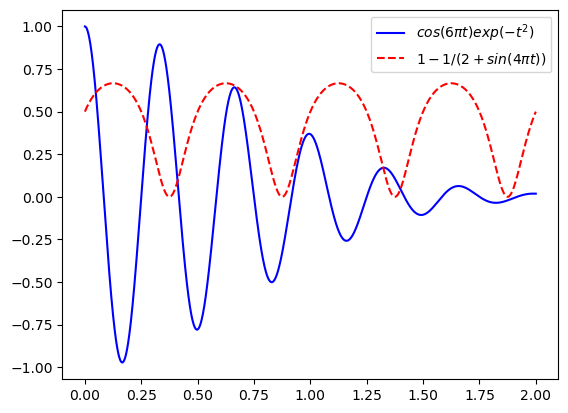

In [44]:
plt.plot(t,X[:,0],'-b',label='$cos(6\pi t)exp(-t^2)$')
plt.plot(t,X[:,1],'--r',label='$1-1/(2+sin(4\pi t))$')
plt.legend(loc='best')
plt.show()

___

### Exercise
`numpy`, `Mathematical functions`, `Conditional statement`, `Functions`

Write a Python function that returns the value of $f(x)$ for input $x \in[0,15]$, where

$$
\begin{equation}
f(x) = \left\{\begin{array}{cc}
1/x \ , & 2\leq x <5 \\
20\sqrt{\ln(0.1 x)+1}/(1+e^{-5\sin(x)}) \ , & 5\leq x\leq 10 \\ 
tan(x) \ , & \text{otherwise} \
\end{array} \right.
\end{equation}
$$

Test your function

**Solution:** We need an `if` statement to define the function over its different subranges. An easy way is to consider single values of $x$ in the conditional statement. Hence, we should use the mathematical functions from `math`. 

In [45]:
def myF(x):
    
    if 2 <= x < 5:
       f = 1./x
    elif 5 <= x <= 10:
       f = 20.*mt.sqrt(mt.log(x/10.)+1.)/(1.+mt.exp(-5.*mt.sin(x)))
    else:
       f = mt.tan(x) 
    
    return f

We can call this function for scalar values of $x$:

In [46]:
print(myF(2.5))
print(myF(0.6))

0.4
0.6841368083416923


If we have an array of $x$ values, we call the above function for each member of that. The returned values are collected in a separate array initilized before the loop:

In [47]:
x = np.linspace(0,15,200)  # values of x

F = np.zeros(len(x))       #initialize an array to collect the values of x

for i in range(len(x)):
    F[i] = myF(x[i])       #call the function for each member of the x array

We can plot $f(x)$ versus $x$:

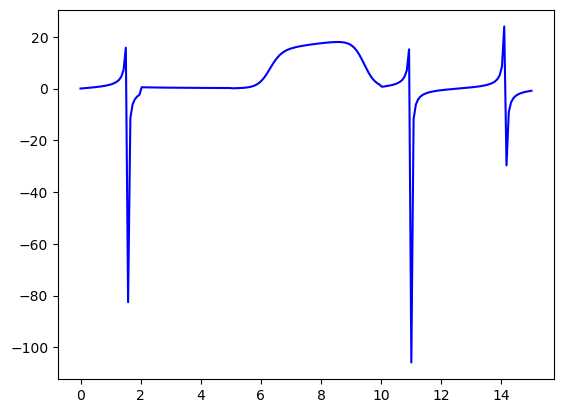

In [48]:
plt.plot(x,F,'-b')
plt.show()

___

### Exercise
`numpy`, `Loops`, `Functions`

Consider a discrete function where its value at each iteration, $x_i$, depends on its value in the previous iteration $x_{i-1}$ through

$$
x_i = 0.5 x_{i-1} + \epsilon_i
$$

where $\epsilon_i$ is a random value from a uniform distribution over $[0,1]$.


Write a Python function that generates $n$ successive values of $x$ for a given initial condition $x_0$.

**Solution:**

In [49]:
def xVals(n,x0):
    
    #initialize an array of size n
    x = np.zeros(n)   
    
    #set the initial value in the 1st element of the array
    x[0] = x0
    
    #generate an array of uniform random numbers
    eps = np.random.rand(n)
    
    #update the values of x, starting from x[1]
    for i in range(1,n):
        x[i] = 0.5*x[i-1]+eps[i]
        
    return x    

Now, let's test the function. 

In [50]:
x1 = xVals(50,-0.1)

print(x1)

[-0.1         0.34536757  0.729716    0.84249157  0.81510394  0.77401584
  1.35846739  1.37812512  1.50334064  1.57748077  0.95066616  1.13240079
  1.25712177  1.40183712  1.60129782  1.48720824  0.7766923   1.36387904
  1.58483361  1.02791367  0.99622263  1.2670233   1.36051341  1.38477265
  0.89220438  0.65872496  0.74277722  0.39895071  0.84769179  1.03365471
  0.95333465  0.91577203  0.51178436  0.84287068  0.79027753  1.29866399
  1.47413049  1.28248355  1.574493    1.44788916  1.17460329  1.29318356
  0.88214474  1.11483111  1.36897482  1.19690293  1.33762665  0.7339006
  1.0070589   1.38101291]


We can plot the array $x$. For this, we need to create an array of size n of indices to be represented on the horizontal axis:


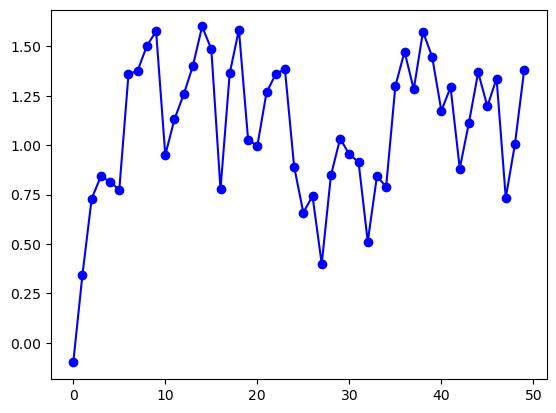

In [51]:
I = np.arange(len(x1))

plt.plot(I,x1,'-ob')
plt.show()

___

### Exercise
`Mathematical functions`, `Functions`

Consider the quadratic equation $ax^2+bx+c=0$ with $a, b, c$ being real numbers and $a\neq0$. From calculus, we know that the two roots of this equations can be obtained from, 

$$
x_{1,2} = \frac{-b\pm\sqrt{b^2-4ac}}{2a}
$$

Write a Python function that takes in real numbers $a\neq0$, $b$, and $c$ and returns roots $x_1$ and $x_2$.

**Solution:**
In the following implementation, we first check if $a\neq 0$ is met. If so, the rest is straightforward. Only be careful that the square root function `sqrt` should be called from `cmath` and not `math`, as it is plausible that the result of this function is a complex number. 

In [52]:
def rootPoly2(a,b,c):
    
    if a == 0.:
       raise ValueError("a cannot be zero.") 
    else:
       d = b**2. - 4.*a*c
       x1 = (-b + cmt.sqrt(d))/(2.*a)
       x2 = (-b - cmt.sqrt(d))/(2.*a)
    
    return x1,x2        

Here are some tests:

In [53]:
x1, x2 = rootPoly2(2.,1.,-5.)
print("roots:",x1,x2)

roots: (1.3507810593582121+0j) (-1.8507810593582121+0j)


In [54]:
x1, x2 = rootPoly2(3.,4.5,7.)
print("roots:",x1,x2)

roots: (-0.75+1.3307266185559425j) (-0.75-1.3307266185559425j)


In [55]:
x1, x2 = rootPoly2(1.,-1,-2.)
print("roots:",x1,x2)

roots: (2+0j) (-1+0j)


___

### Exercise 
`numpy arrays`, `Mathematical functions`, `Plotting`

Chebyshev polynomials of order $k$ over real values of $x \in [-1,1]$ are defined as, 

$$
\begin{equation}
T_k(x) = \cos(k \arccos x) \ , \ \ k=0, 1, 2, \ldots \ .
\end{equation}
$$

Write a Python function that returns the value of $T_k(x)$ for input $k$ and $x$. Your function should work for both single values and multiple values (arrays) of $x$. Additionally, plot the Chebyshev polynomials for $k=1,2,..,5$ for 200 evenly-spaced values of $x$ over $[-1,1]$.

**Solution:**
In the following imeplementation, we first check that the input $k$ is a non-negative integer number. Assuming the input $x$ can be a `numpy` array, then the `numpy` mathematical functions are used. 

In [56]:
def chebyshevPoly(k,x):
    if k == int(k) and k >= 0: 
       T = np.cos(k * np.arccos(x)) 
    else:
        raise ValueError("k should be a non-negative integer")
    return T    

This function can be called for single values of $x$ over $[-1,1]$:

In [57]:
print(chebyshevPoly(2,-0.58))
print(chebyshevPoly(5,0.58))

-0.3272000000000005
0.0479308287999998


The function can also be used for `numpy` arrays of $x$:

In [58]:
x = np.linspace(-1.,1.,200)

T1 = chebyshevPoly(1,x)
T2 = chebyshevPoly(2,x)
T3 = chebyshevPoly(3,x)
T4 = chebyshevPoly(4,x)
T5 = chebyshevPoly(5,x)

These can be plotted in a single plot with appropriate labling:

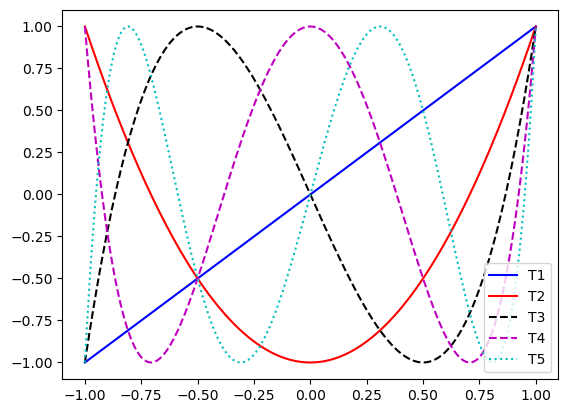

In [59]:
plt.plot(x,T1,'-b',label='T1')
plt.plot(x,T2,'-r',label='T2')
plt.plot(x,T3,'--k',label='T3')
plt.plot(x,T4,'--m',label='T4')
plt.plot(x,T5,':c',label='T5')

plt.legend(loc='best')
plt.show()

___

### Exercise
`numpy`, `Mathematical functions`, `Functions`, `Loops`

Write Python functions that returns the sum over a finite number of values of a given sequence. The inputs to the function is:

* `n`: integer, number of values in the sequence. 

Implement your functions for the following sequences:

   1. $x_n=exp(-n^2)$
   2. $x_n = (1+\frac{1}{n})^n$

In [60]:
def ex1_a(n):
    s=0.
    for i in range(n):
        s += mt.exp(-i**2.)
    return s    

An alternative implementation using `numpy`:

In [61]:
def ex1_b(n):
    nAr = np.arange(n)
    s = np.sum(np.exp(-nAr**2.))
    return s 

We can verify these two implementations return the same values:

In [62]:
print(ex1_a(10))
print(ex1_b(10))

1.3863186024133263
1.386318602413326


You can modify the above scripts for $x_n = (1+\frac{1}{n})^n$.

___

### Exercise
`numpy`, `Plotting`

1. Using `numpy` built-in functions, create an array of positive integer values of $n$ over $[10,100]$.
2. Evaluate $F_n$ defined below at the resulting array of $n$.
3. Plot values of $F_n$ versus $n$.

$$
F_n = 
\left[
\frac{1}{\sqrt{5}} 
\left(
\left( \frac{1+\sqrt{5}}{2}\right)^n 
- 
\left( \frac{1-\sqrt{5}}{2}\right)^n
\right)
\right]^{1/n}
$$



**Solution:**
An efficient way of creating an array of positive $n$ over the given range is to use `numpy.arange`:

In [63]:
n = np.arange(10,100,10)
print(n)

[10 20 30 40 50 60 70 80 90]


Evaluate the given function for this array:

In [64]:
t1 = (1. + mt.sqrt(5))/2.
t2 = (1. - mt.sqrt(5))/2.
Fn = ((t1**n - t2**n)/mt.sqrt(5))**(1/n)

Make a plot (only discrete values are shown by markers):

[1.49291908 1.55422321 1.57520884 1.58580767 1.59220118 1.59647782
 1.5995396  1.60183979 1.60363111]


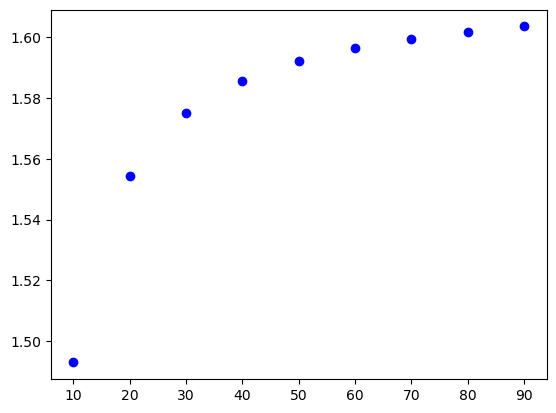

In [65]:
print(Fn)
plt.plot(n,Fn,'ob')

___

### Exercise
`numpy`, `Conditional statements`, `Loops`, `Plotting`

Consider the following two functions:

$$
f(x) = x^2 -2 \quad\quad,\quad\quad g(x)=x
$$

From analytical solution, we know that the intersection of these two function is at $x=-1.0$ and $x=2.0$. 

* Write a Python script that searches values of $x$ over $[-3.0,3.0]$ to (approximately) find these two roots. You can try different tolerances for getting close to the exact values of the intersection points. 

**Solution:** Consider the following algorithm

<div class="alert alert-block alert-success">
<b>Algorithm:</b> 

Inputs: $n$ and tolerance $\epsilon$
    
1. Create a set of $n$ evenly-spaced values of $x\in[-3.0,3.0]$ $\to$ `x`
2. Evaluate $f(x)$ and $g(x)$ at `x` $\to$ `f`, `g` <br>
3. Create an empty list `r`    
4. Loop over values of `f` and `g` $\to$ `f[i]` and `g[i]` <br>
   a. Is $|f_i - g_i|\leq \epsilon$ <br>
          a.i. If yes, append `x[i]` to `r`     
</div>

Set the inputs:

In [66]:
eps = 1.e-3   #tolerance epsilon
n= 1000       #data resolution (= arrays' size)

Create array $x$:

In [67]:
x = np.linspace(-3.,3.,n)

Evaluate $f(x)$ and $g(x)$ at the generated $x$ array:

In [68]:
f = x**2 - 2.
g = x

Find the intersections:

In [69]:
r = []
for i in range(len(x)):
    if abs(f[i] - g[i]) < eps:
       r.append(x[i])
    
print(r)    

[-1.0]


Plotting

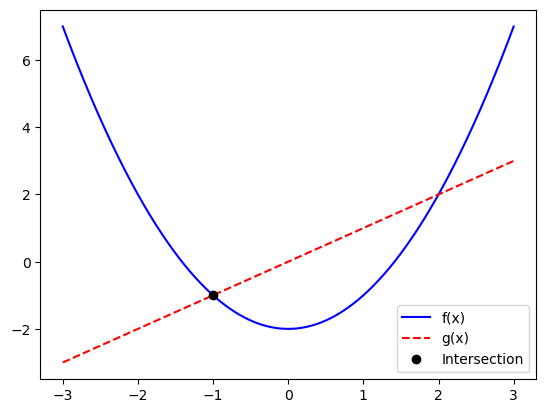

In [70]:
r = np.asarray(r)


plt.plot(x,f,'-b',label='f(x)')
plt.plot(x,g,'--r',label='g(x)')
plt.plot(r,r,'ok',label='Intersection')
plt.legend(loc='best')
plt.show()

Depending on the resolution of $x$ (value of `n`) and chosen tolerance `eps`, you may find various approximations for the intersection points. 

___

### Exercise
`numpy`, `Functions`, `Loops`

A polynomial of order $n$ is defined as, 

$$
P_n(x) = a_0 + a_1 x+ a_2 x^2 +\cdots + a_n x^n = \sum_{k=0}^n a_k x^k
$$

The vector of coefficients of this polynomial is $\mathbf{a}=[a_0,a_1,a_2,\cdots,a_n]$. 

Write a Python function with $x$ and $\mathbf{a}$ as the inputs, that returns the value of $P_n(x)$. Test your implementations for the following polynomials:

$$
P_4(x)=1 +0.5x^2+3x^3-6.7 x^4 \quad\quad\,,\quad\quad
P_5(x)=13.6 -2.5x+2x^2-8.45x^3-6.7 x^5
$$

where
* $x$ is a real number. 
* $x$ is an array of real numbers over [-1,2].

**Solution:**
Since the function should work for both scalar and arrays of $x$, the best solution is to consider `P` to be a `numpy` array of the same size of $x$. This means, all the input $x$ should be 1D `numpy` arrays, even the scalar ones. The latter should be considered as arrays of size 1. 

In [71]:
def myPolyFun(a,x):
    n = len(a)
    P = np.zeros(len(x))
    
    for i in range(n):
        P += a[i]*x**i
        
    return P    

Let's evaluate the function for the given $P_4(x)$ and $P_5(x)$ at a scalar $x$ that is defined as an array:

In [72]:
x1 = np.array([1.5])

P4 = myPolyFun(a=[1.0,0.0,0.5,3.0,-6.7], x=x1)
P5 = myPolyFun(a=[13.6,-2.5,2.0,-8.45,0.0,-6.7], x=x1)

print('P4 =', P4)
print('P5 =', P5)

P4 = [-21.66875]
P5 = [-65.046875]


For multiple values of $x\in[-1.,2.]$, we have

In [73]:
x2 = np.linspace(-1.,2.,100)

P4 = myPolyFun(a=[1.0,0.0,0.5,3.0,-6.7], x=x2)
P5 = myPolyFun(a=[13.6,-2.5,2.0,-8.45,0.0,-6.7], x=x2)

print('P4 =', P4)
print('P5 =', P5)

P4 = [-8.20000000e+00 -7.18935089e+00 -6.26324536e+00 -5.41691141e+00
 -4.64571266e+00 -3.94514829e+00 -3.31085308e+00 -2.73859743e+00
 -2.22428728e+00 -1.76396421e+00 -1.35380535e+00 -9.90123457e-01
 -6.69366847e-01 -3.88119445e-01 -1.43100763e-01  6.88340960e-02
  2.50694439e-01  4.05353982e-01  5.35550850e-01  6.43887578e-01
  7.32831108e-01  8.04712793e-01  8.61728395e-01  9.05938085e-01
  9.39266444e-01  9.63502459e-01  9.80299531e-01  9.91175466e-01
  9.97512482e-01  1.00055720e+00  1.00142067e+00  1.00107832e+00
  1.00037001e+00  1.00000000e+00  1.00053697e+00  1.00241399e+00
  1.00592856e+00  1.01124257e+00  1.01838234e+00  1.02723858e+00
  1.03756641e+00  1.04898539e+00  1.06097944e+00  1.07289693e+00
  1.08395062e+00  1.09321768e+00  1.09963969e+00  1.10202265e+00
  1.09903695e+00  1.08921741e+00  1.07096324e+00  1.04253808e+00
  1.00206995e+00  9.47551312e-01  8.76839014e-01  7.87654321e-01
  6.77582908e-01  5.44074858e-01  3.84444664e-01  1.95871226e-01
 -2.46021447e-02 -2.

___

### Exercise
`numpy`, `Functions`, `Loops`

A geometric series is defined as,

$$
S_n = 1 + ar + ar^2 + \cdots + ar^n = \sum_{k=0}^n ar^k \,,
$$

where $a$ is the initial value and $r$ is the common ratio. If $|r|<1$ when $n\to \infty$, the summation $S_n$ converges to $S=a/(1-r)$. For any finite value of $n$, the error between the summation $S_n$ and the 1exact value $S$ can be measured by $error=|S_n-S|/|S|$. 

Write a Python script that for given values of $a$ and $r$ computes $S_n$. The code should stop once the $error$ is less than a given threshold $\epsilon$, i.e. when $error <\epsilon$. Your code should print the computed value of $S_n$ and the number of terms required in the summation to reach the preset error limit. 

**Solution:** We can consider the following algorithm:

<div class="alert alert-block alert-success">
<b>Algorithm:</b> 

Inputs: real numbers $a$, $r$ ($|r|<1$), and $\epsilon$

1. Initialize the value of $S_n \to 0$ and error $e \to 1.0$ (arbitrarily larger than $\epsilon$)
2. While $e < \epsilon$    
   a. Add $ar^k$ to $S_n$ <br>
   b. Updte the error $e$      
3. return $S_n$     
</div>

First, we need to define the inputs:

In [74]:
a = 0.1
r = 0.2   # must be less than 1
eps = 1.e-8    #epsilon

The exact value of $S$ is computed given the above expression. This is required to calculate error $e$:

In [75]:
S = a/(1-r)    #Exact value of S

An implemention can be by using a `while` loop:

In [76]:
Sn = 0.0    #initilize Sn to zero
e = 1.0   #initialize the error - it should be something larger than eps
k = 0       #initialize the counter in the summation

while e >= eps:    #The loop continues until error is not smaller than epsilon
    
    Sn += a*r**k     #Update the summation
    k += 1           #Increase the counter by 1
    e = abs(S-Sn)/abs(S)  #Compute the error

Here are the outcome of the loop:

In [77]:
print('Exact S = ',S)
print('Computed Sn =',Sn)
print('Final error =',e)
print('Number of terms in the summation =',k)

Exact S =  0.125
Computed Sn = 0.12499999948800003
Final error = 4.095999761588587e-09
Number of terms in the summation = 12


An alternative implementation is to use a `for` loop. In this case, two main points should be considered:
1. We should use `break` if the error becomes less than the preset threshold. 
2. Since it is not clear how many terms should considered in the summation, the number of iterations of the `loop` is not known. To rectify this, we can set an arbitrary large upper limit for `n`.

In [78]:
n = 1000    #An arbitrary large number

In [79]:
Sn = 0.0    #initilize Sn to zero

for k in range(n):    #The loop continues until n-1 unless it breaks due to error being less than the threshold
    Sn += a*r**k      #Update the summation
    e = abs(S-Sn)/abs(S)  #Compute the error
    if e < eps:
       break 

The outcome:

In [80]:
print('Exact S = ',S)
print('Computed Sn =',Sn)
print('Final error =',e)
print('Number of terms in the summation =',k+1)

Exact S =  0.125
Computed Sn = 0.12499999948800003
Final error = 4.095999761588587e-09
Number of terms in the summation = 12


Clearly, the outcome of the above two implementations are the same. However, the implementation with the `while` loop may be more intuitive. 

___

### Exercise
`numpy`, `Functions`, `Loops`

Similar to the previous exercise, find the number of terms required for approximating $e^x$ for $|x|<1$ by the following summation:

$$
e^x \approx \sum_{k=0}^n \frac{x^k}{k!}\,,\quad\quad
|x|<1
$$



**Solution:**
We just follow the structure from the previous exercise. You need a function for evaluating $k!$ which has been developed in one the earlier exercises (copied below for reference).

In [81]:
def factorial(n):
    fact=1
    
    while n > 0:
       fact *= n
       n -= 1
        
    return fact        

In [82]:
# inputs
x = 0.5  # Note: |x|<1
eps = 1.e-8

#exact value
S = mt.exp(x)

In [83]:
#initialization
Sn = 0.0   #summation
e = 1.0     #error
k = 0     #index in the summation

while e > eps:
      Sn += x**k/factorial(k)
      e = abs(S-Sn)/abs(S)  
      k += 1

Results:

In [84]:
print('Exact S = ',S)
print('Computed Sn =',Sn)
print('Final error =',e)
print('Number of terms in the summation =',k+1)

Exact S =  1.6487212707001282
Computed Sn = 1.6487212650359622
Final error = 3.4354903559251164e-09
Number of terms in the summation = 10


___